# HW2 · Cut Cross-Entropy: от формулы к измерению

Воспроизведение вычисления loss и градиентов из **Cut Your Losses in Large-Vocabulary Language Models**
([статья, arXiv v2](https://arxiv.org/html/2411.09009v2), [локальный PDF](sources/paper.pdf)).
Формат — как на семинаре: объяснение → код → наблюдение → границы вывода.
Подробные выкладки и таблицы: [отчёт](REPORT.md). Материал для выступления: [презентация](presentation.html).

**Что действительно сделано:** синтетическая серия, classifier head на Gemma 2 2B / Alpaca,
проверка loss/gradients, CUDA timings, allocated memory и 15 profiler-трасс.
Обучение полной LLM и проверка её качества не выполнялись.

<a id="section-1"></a>

## 1. Как пройти notebook

### Маршрут чтения за 10 минут

1. [§2 — формула CE и проверяемые gradients](#section-2).
2. [§4 — численная корректность](#section-4).
3. [§§10–12 — основной эксперимент: classifier head Gemma / Alpaca](#section-10).
4. [§§5–6 — синтетическая сетка и зависимость от shape](#section-5).
5. [§14 — выводы и ограничения](#section-14).

[§§7–9](#section-7) — дополнительная диагностика и profiler; [§13](#section-13) — сверка артефактов.
Это маршрут **чтения**. Для выполнения Run All ячейки идут сверху вниз: определения используются ниже.

**Главный локальный результат:** на извлечённых Gemma 2 2B / Alpaca activations,
N=1024, V=256000, D=2304, BF16, softcap=30, classifier-head forward+backward:
extra peak **3500.001 → 1132.734 MiB**, median **62.751 → 31.877 ms** (baseline_author → CCE).
Backbone не входит в измерение. Уменьшение extra peak не равно уменьшению полной VRAM;
подробные значения full allocated peak приведены в §12. Runtime benefit зависит от shape и режима.

По умолчанию **Run All** выполняет пять CPU-проверок формул, пересчитывает таблицы и графики
из сохранённых JSON и сверяет 15 сырых трасс с их summaries. Это анализ уже выполненных
экспериментов, а не новый GPU benchmark. Он работает без Triton, модели и локальных `.py`.

Для новых измерений включите нужные флаги ниже и выполните notebook сверху вниз.
Код генерации данных, измерений, профилирования и подготовки Gemma находится в ячейках.
CCE-ядра берутся из закреплённого авторского репозитория: это внешняя зависимость,
как PyTorch и Triton. Установка окружения описана в [README](README.md).

In [1]:
from pathlib import Path
from types import SimpleNamespace
from datetime import datetime, timezone
from collections import Counter, defaultdict
import csv, gc, gzip, hashlib, importlib, importlib.metadata, json, os
import platform, random, subprocess, sys, time, unittest
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Открывать из HW2/ или корня репозитория.
ROOT = Path.cwd().resolve()
if not (ROOT / 'results/main/measurements.json').exists():
    ROOT = ROOT / 'HW2'
assert (ROOT / 'results/main/measurements.json').exists(), 'Откройте notebook из HW2 или корня репозитория'

RUN_GPU_SMOKE = False
RUN_SYNTHETIC = False
RUN_DIAGNOSTICS = False
RUN_PROFILER = False
RUN_CACHE = False
DOWNLOAD_REAL = False
PREPARE_REAL = False
RUN_REAL = False

# Новый каталог для каждого Run All; исходные результаты не перезаписываются.
RUN_ROOT = ROOT / 'results/notebook_runs' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
GPU_ENABLED = any((RUN_GPU_SMOKE, RUN_SYNTHETIC, RUN_DIAGNOSTICS,
                   RUN_PROFILER, RUN_CACHE, PREPARE_REAL, RUN_REAL))
def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding='utf-8'))

def table(rows, columns):
    def fmt(value):
        return f'{value:.6g}' if isinstance(value, float) else str(value)
    lines = ['| ' + ' | '.join(columns) + ' |', '| ' + ' | '.join(['---'] * len(columns)) + ' |']
    lines += ['| ' + ' | '.join(fmt(r.get(k, '—')) for k in columns) + ' |' for r in rows]
    display(Markdown('\n'.join(lines)))

print('Режим:', 'новые GPU-запуски + анализ архива' if GPU_ENABLED else 'CPU-проверки + анализ сохранённых измерений')
print('Текущий Python:', platform.python_version(), '| PyTorch:', torch.__version__)

Режим: CPU-проверки + анализ сохранённых измерений
Текущий Python: 3.11.9 | PyTorch: 2.11.0+cu128


### Зафиксированная среда экспериментов

Следующая ячейка читает **историческую среду**, а не определяет текущую GPU.
В старых environment-файлах оставлены SHA256 исходных рабочих скриптов: эти записи не переписаны
задним числом. Публичная версия кода теперь находится в notebook. Новые запуски записывают
хеш всех его code cells, свой timestamp и свою среду. Побитовое повторение timings не предполагается.

In [2]:
saved_environment = read_json('results/main/environment.json')
table([{key: saved_environment[key] for key in ('python', 'torch', 'cuda', 'triton', 'gpu', 'driver', 'upstream_commit')}],
      ['python', 'torch', 'cuda', 'triton', 'gpu', 'driver', 'upstream_commit'])

| python | torch | cuda | triton | gpu | driver | upstream_commit |
| --- | --- | --- | --- | --- | --- | --- |
| 3.11.9 | 2.11.0+cu128 | 12.8 | 3.6.0 | NVIDIA GeForce RTX 5070 Ti | 591.86 | 3de376c106a1916bc5e1b619f9c77c87a461ee1c |

<a id="section-2"></a>

## 2. Постановка и cross-entropy

Используем PyTorch-ориентацию: $E\in\mathbb R^{N\times D}$ — embeddings,
$C\in\mathbb R^{V\times D}$ — classifier, $Z=EC^\top$.
Для множества валидных позиций $I=\{i:y_i\ne-100\}$, $M=|I|$:

$$L=\frac1M\sum_{i\in I}\left(\log\sum_{j=1}^V e^{Z_{ij}}-Z_{i,y_i}\right).$$

Обычный baseline материализует $N\times V$ logits. CCE вычисляет нормализатор блоками
и не сохраняет полную матрицу logits. В backward нужные блоки вычисляются повторно.
Подробный вывод от вероятности класса до loss — в отчёте, §§2–5.

### Устойчивое объединение блоков

Для блока $A$ храним $m_A=\max_{j\in A}z_j$ и $s_A=\sum_{j\in A}e^{z_j-m_A}$.
При объединении с блоком $B$:

$$m=\max(m_A,m_B),\qquad s=s_Ae^{m_A-m}+s_Be^{m_B-m},\qquad \operatorname{LSE}=m+\log s.$$

Ниже эквивалентная запись через `logaddexp`. Это учебная CPU-реализация формулы;
её autograd может сохранять промежуточные тензоры, поэтому её память не выдаётся за память CCE.

In [3]:
def online_lse(blocks):
    """Merge log-sum-exp of blocks along their last dimension."""
    result = None
    for block in blocks:
        partial = torch.logsumexp(block, dim=-1)
        result = partial if result is None else torch.logaddexp(result, partial)
    if result is None:
        raise ValueError('At least one block required')
    return result

In [4]:
def streaming_loss(e, c, y, block_size=128):
    """FP64 teaching reference; PyTorch autograd retains intermediates.

    Therefore this function is NOT used for memory/speed claims.
    """
    if block_size < 1:
        raise ValueError('block_size must be positive')
    mask = y != -100
    if not mask.any():
        raise ValueError('Mean loss over zero valid tokens is undefined')
    e, y = e[mask], y[mask]
    lse = online_lse(e @ part.T for part in c.split(block_size))
    target = (e * c[y]).sum(-1)
    return (lse-target).mean()

### Backward и размеры буферов

Обозначим $P=\operatorname{softmax}(Z)$, $G_{ij}=(P_{ij}-[j=y_i])/M$ для $i\in I$,
а для ignored positions положим $G_{ij}=0$. Тогда

$$\nabla_E L=GC,\qquad \nabla_C L=G^\top E.$$

При softcap $\widetilde Z=s\tanh(Z/s)$ дополнительно умножаем производную на
$1-\tanh^2(Z/s)$. Это объясняет, почему порядок BF16/FP32 операций softcap имеет значение.
Полная BF16-матрица logits занимает $2NV$ bytes; FP32 — $4NV$.
Размеры отдельных тензоров нельзя отождествлять с пиком allocator.

In [5]:
def analytical_gradients(e, c, y):
    valid = y != -100
    if not valid.any():
        raise ValueError('No valid tokens')
    p = (e @ c.T).softmax(-1)
    p[valid, y[valid]] -= 1
    p[~valid] = 0
    p /= valid.sum()
    return p @ c, p.T @ e

In [6]:
def memory_terms(n,v,d,bytes_per_value=2):
    if min(n,v,d)<1:
        raise ValueError('Dimensions must be positive')
    return dict(logits_bf16=bytes_per_value*n*v,logits_fp32=4*n*v,
                embeddings=bytes_per_value*n*d,classifier=bytes_per_value*v*d,
                lse_fp32=4*n,gradients=bytes_per_value*(n*d+v*d))

### Проверяем формулы, а не только переписываем их

Пять CPU-тестов: ручные gradients против autograd; blockwise loss и gradcheck;
устойчивость при больших logits; арифметика размеров; обработка отсутствия валидных targets.
Эти проверки выполняются при каждом Run All и не требуют GPU.

In [7]:
class EquationsTest(unittest.TestCase):
    def setUp(self):
        torch.manual_seed(42)
        self.e=torch.randn(5,3,dtype=torch.float64,requires_grad=True)
        self.c=torch.randn(7,3,dtype=torch.float64,requires_grad=True)
        self.y=torch.tensor([0,6,-100,2,2])

    def test_loss_and_manual_gradients(self):
        loss=F.cross_entropy(self.e @ self.c.T,self.y)
        loss.backward()
        ge,gc=analytical_gradients(self.e.detach(),self.c.detach(),self.y)
        torch.testing.assert_close(ge,self.e.grad,atol=1e-12,rtol=1e-12)
        torch.testing.assert_close(gc,self.c.grad,atol=1e-12,rtol=1e-12)
        for block in (1,3,7,20):
            torch.testing.assert_close(streaming_loss(self.e,self.c,self.y,block),loss,atol=1e-12,rtol=1e-12)

    def test_finite_difference(self):
        self.assertTrue(torch.autograd.gradcheck(lambda e,c: streaming_loss(e,c,self.y,3),(self.e,self.c)))

    def test_stability(self):
        z=torch.tensor([[1000.,1001.,-1000.,999.]],dtype=torch.float64)
        torch.testing.assert_close(online_lse(z.split(2,dim=-1)),torch.logsumexp(z,-1))
        self.assertTrue(torch.isinf(z.exp()).any())

    def test_memory(self):
        terms=memory_terms(8192,256000,2304)
        self.assertEqual(terms['logits_fp32'],8_388_608_000)
        self.assertEqual(terms['lse_fp32'],32768)

    def test_invalid(self):
        with self.assertRaises(ValueError):
            streaming_loss(self.e,self.c,torch.full_like(self.y,-100))

cpu_checks = unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(EquationsTest))
assert cpu_checks.wasSuccessful()

test_finite_difference (__main__.EquationsTest.test_finite_difference) ... 

ok


test_invalid (__main__.EquationsTest.test_invalid) ... 

ok


test_loss_and_manual_gradients (__main__.EquationsTest.test_loss_and_manual_gradients) ... 

...

test_memory (__main__.EquationsTest.test_memory) ... 

ok


test_stability (__main__.EquationsTest.test_stability) ... 

ok


----------------------------------------------------------------------
Ran 5 tests in 0.922s

OK


<a id="section-3"></a>

## 3. Авторские CCE-ядра и варианты

Используем commit `3de376c106a1916bc5e1b619f9c77c87a461ee1c` репозитория
[Apple CCE](https://github.com/apple-aiml-research/ml-cross-entropy/tree/3de376c106a1916bc5e1b619f9c77c87a461ee1c).
Ядра не изменены. На Windows адаптируется только определение версии `triton-windows`.

| Режим | Что вычисляется |
|---|---|
| baseline | BF16 matmul → FP32 logits/softcap → PyTorch CE |
| cce | авторский default |
| cce_no_filter | `filter_eps=None` |
| cce_exact | авторский preset: без filtering, с FP32 accumulation |
| cce_filter_fp32 | default filtering + FP32 accumulation |

`exact` — название preset, не обещание отсутствия floating-point rounding.
Отключение filtering меняет также служебные действия, включая sorting;
сравнение default/no-filter не изолирует стоимость одного threshold.

In [8]:
UPSTREAM_COMMIT = '3de376c106a1916bc5e1b619f9c77c87a461ee1c'
VENDOR = ROOT / 'vendor/ml-cross-entropy'
CACHE = Path('C:/tmp/enn-hw2-cache') if platform.system() == 'Windows' else ROOT / '.cache'
os.environ.setdefault('TRITON_CACHE_DIR', str(CACHE / 'triton'))
os.environ.setdefault('TORCHINDUCTOR_CACHE_DIR', str(CACHE / 'inductor'))
os.environ.setdefault('HF_HUB_DISABLE_XET', '1')

if GPU_ENABLED:
    assert torch.cuda.is_available(), 'Нужна CUDA GPU; CPU fallback для benchmark отсутствует'
    if not VENDOR.exists():
        VENDOR.parent.mkdir(parents=True, exist_ok=True)
        subprocess.run(['git', 'clone', 'https://github.com/apple-aiml-research/ml-cross-entropy.git', str(VENDOR)], check=True)
        subprocess.run(['git', '-C', str(VENDOR), 'checkout', UPSTREAM_COMMIT], check=True)
    actual_commit = subprocess.check_output(['git', '-C', str(VENDOR), 'rev-parse', 'HEAD'], text=True).strip()
    assert actual_commit == UPSTREAM_COMMIT, 'Проверьте закреплённый commit CCE'
    assert not subprocess.check_output(['git', '-C', str(VENDOR), 'diff', 'HEAD', '--', 'cut_cross_entropy'], text=True).strip(), 'Ядра CCE изменены'
    sys.path.insert(0, str(VENDOR))
    import triton
    import triton.testing
    if platform.system() == 'Windows':
        from packaging.version import Version
        module = importlib.import_module('cut_cross_entropy.linear_cross_entropy')
        module.is_triton_3_2 = lambda: triton.__version__.split('.')[:2] == ['3', '2']
        backward = importlib.import_module('cut_cross_entropy.cce_backward')
        backward.is_triton_greater_or_equal_3_2_0 = lambda: Version(triton.__version__) >= Version('3.2.0')
        autotune = importlib.import_module('cut_cross_entropy.tl_autotune')
        autotune.is_triton_greater_or_equal_3_2_0 = backward.is_triton_greater_or_equal_3_2_0
    print('GPU:', torch.cuda.get_device_name(), '| CCE commit:', actual_commit)
else:
    print('Импорт CCE/Triton пропущен: читаем сохранённые результаты.')

Импорт CCE/Triton пропущен: читаем сохранённые результаты.


In [9]:
def configure():
    torch.manual_seed(42)
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

In [10]:
def loss_fn(method, e, c, y, softcap=None):
    if method == 'baseline':
        z = (e @ c.T).float()
        if softcap is not None:
            z = softcap * torch.tanh(z / softcap)
        return F.cross_entropy(z, y, ignore_index=-100)
    from cut_cross_entropy import linear_cross_entropy
    opts = dict(impl='cce', softcap=softcap)
    if method == 'cce_no_filter':
        opts['filter_eps'] = None
    elif method == 'cce_exact':
        opts['impl'] = 'cce_exact'
    elif method == 'cce_filter_fp32':
        opts.update(accum_e_fp32=True, accum_c_fp32=True)
    elif method != 'cce':
        raise ValueError(method)
    return linear_cross_entropy(e, c, y, **opts)

In [11]:
def make_data(n, v, d, seed=42, scale=1.0, dtype=torch.bfloat16):
    gen = torch.Generator(device='cuda').manual_seed(seed)
    # Same D**(-1/4) scaling idea as upstream synthetic benchmark.
    e = (torch.randn(n, d, device='cuda', dtype=dtype, generator=gen) / d**0.25 * scale).requires_grad_()
    c = (torch.randn(v, d, device='cuda', dtype=dtype, generator=gen) / d**0.25).requires_grad_()
    y = torch.randint(v, (n,), device='cuda', generator=gen)
    return e, c, y

In [12]:
METHODS = ('baseline', 'cce', 'cce_no_filter', 'cce_exact')
configure()
def write_json(path, value):
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')

### Протокол происхождения новых результатов

Code cells хешируются независимо от сохранённых outputs. Существующие измерения остаются
в `results/main`, `results/gemma2` и каталогах profiler. Новые серии попадут в
`results/notebook_runs/<UTC timestamp>/`; таблицы ниже всегда явно подписаны как архивные.

In [13]:
def notebook_code_sha256():
    notebook = json.loads((ROOT / 'cce_reproduction.ipynb').read_text(encoding='utf-8'))
    sources = [''.join(c['source']) for c in notebook['cells'] if c['cell_type'] == 'code']
    return hashlib.sha256('\n\n'.join(sources).encode('utf-8')).hexdigest()

def new_output(name):
    path = RUN_ROOT / name
    path.mkdir(parents=True, exist_ok=False)
    return path


def environment(args):
    props = torch.cuda.get_device_properties(0)
    def cmd(*parts):
        return subprocess.check_output(parts, text=True, encoding='utf-8').strip()
    return dict(timestamp_utc=datetime.now(timezone.utc).isoformat(),
                python=platform.python_version(), platform=platform.platform(),
                torch=torch.__version__, cuda=torch.version.cuda, triton=triton.__version__,
                triton_distribution=importlib.metadata.version('triton-windows' if platform.system() == 'Windows' else 'triton'),
                gpu=props.name, vram_bytes=props.total_memory, capability=list(torch.cuda.get_device_capability()),
                driver=cmd('nvidia-smi', '--query-gpu=driver_version', '--format=csv,noheader'),
                upstream_commit=cmd('git', '-C', str(VENDOR), 'rev-parse', 'HEAD'),
                repository_base_commit=cmd('git', 'rev-parse', 'HEAD'),
                notebook_code_sha256=notebook_code_sha256(),
                tf32=False, dtype='bfloat16', args=vars(args),
                windows_adaptation='version probe only; ASCII cache path; kernels unmodified')

<a id="section-4"></a>

## 4. Корректность CCE: loss и оба градиента

В синтетической серии 3 seeds × 4 задачи × 5 методов = 60 checks.
Проверяются хвостовые блоки, ignored labels, logits разных масштабов и softcap.
Reference использует **те же BF16 входы**, приведённые к FP64.
Допуски: `abs Δloss < 0.05`, `relative L2 < 0.05` для каждого градиента.
Публикуем величины ошибок: бинарный `passed` сам по себе не означает точность обучения LLM.

In [14]:
def errors(actual, ref):
    a, r = actual.detach().double(), ref.detach().double()
    return dict(max_abs=(a-r).abs().max().item(),
                relative_l2=((a-r).norm()/r.norm().clamp_min(1e-30)).item())

In [15]:
def correctness(out):
    rows = []
    # Tail blocks, ignored labels, normal/peaked logits and softcap are explicit.
    for seed in (42, 43, 44):
        for n,v,d,scale,cap,ignored in ((37,257,64,1,None,True),
                (128,4096,128,1,None,False), (128,4096,128,4,None,False),
                (67,1025,128,4,30.0,True)):
            e,c,y = make_data(n,v,d,seed,scale)
            if ignored:
                y[::7] = -100
            er,cr = e.detach().double().requires_grad_(), c.detach().double().requires_grad_()
            z = er @ cr.T
            if cap:
                z = cap * torch.tanh(z/cap)
            reference = F.cross_entropy(z,y)
            reference.backward()
            for method in (*METHODS, 'cce_filter_fp32'):
                e.grad = c.grad = None
                value = loss_fn(method,e,c,y,cap)
                value.backward()
                row = dict(seed=seed,n=n,v=v,d=d,scale=scale,softcap=cap,ignored=ignored,
                           method=method,loss=value.item(),reference_loss=reference.item(),
                           loss_abs=abs(value.item()-reference.item()),
                           e=errors(e.grad,er.grad),c=errors(c.grad,cr.grad))
                # Error budgets declared independently of observed numbers.
                # Mixed-precision checks, not a claim of bitwise equivalence.
                row['passed'] = row['loss_abs'] < 0.05 and row['e']['relative_l2'] < 0.05 and row['c']['relative_l2'] < 0.05
                rows.append(row)
            del e,c,y,er,cr,z,reference,value
    write_json(out/'correctness.json', rows)
    print('correctness:',sum(r['passed'] for r in rows),'/',len(rows),flush=True)
    return rows

In [16]:
if RUN_GPU_SMOKE:
    smoke_out = new_output('smoke')
    write_json(smoke_out / 'environment.json', environment(SimpleNamespace(mode='notebook_smoke')))
    fresh_checks = correctness(smoke_out)
    assert len(fresh_checks) == 60 and all(r['passed'] for r in fresh_checks)
else:
    print('Новая GPU-проверка выключена. Для неё: RUN_GPU_SMOKE=True.')

saved_checks = read_json('results/main/correctness.json')
assert len(saved_checks) == 60 and all(r['passed'] for r in saved_checks)
display(Markdown('**Архив: максимальные ошибки по 12 задачам для каждого метода.**'))
table([dict(method=m, loss_abs=max(r['loss_abs'] for r in saved_checks if r['method']==m),
            dE_relL2=max(r['e']['relative_l2'] for r in saved_checks if r['method']==m),
            dC_relL2=max(r['c']['relative_l2'] for r in saved_checks if r['method']==m))
       for m in (*METHODS, 'cce_filter_fp32')], ['method','loss_abs','dE_relL2','dC_relL2'])

Новая GPU-проверка выключена. Для неё: RUN_GPU_SMOKE=True.


**Архив: максимальные ошибки по 12 задачам для каждого метода.**

| method | loss_abs | dE_relL2 | dC_relL2 |
| --- | --- | --- | --- |
| baseline | 0.00223675 | 0.0060259 | 0.00600334 |
| cce | 0.00223675 | 0.0082192 | 0.00595119 |
| cce_no_filter | 0.00223675 | 0.00818668 | 0.00595119 |
| cce_exact | 0.00223675 | 0.00571349 | 0.00595119 |
| cce_filter_fp32 | 0.0022358 | 0.00571444 | 0.00595119 |

<a id="section-5"></a>

## 5. Измерение времени и памяти

CUDA асинхронна: CPU wall time вокруг вызова не равен GPU latency. Используем CUDA events
после прогрева, синхронизируем конец каждого sample. JIT исключается прогревом.
В каждой точке 5 warmup и 3 × 10 samples. Сохраняются все samples, median, p10 и p90.

Память измеряется отдельной итерацией: `base = memory_allocated`, сброс peak,
затем операция и `peak = max_memory_allocated`. `extra = peak − base`.
Входы уже существуют до base; в forward+backward extra включает gradients.
Это PyTorch allocated memory, не полная VRAM процесса. MiB = 2²⁰ bytes.

In [17]:
def measure(method,kind,e,c,y,warmup,repeats,rounds):
    def operation():
        e.grad = c.grad = None
        loss = loss_fn(method,e,c,y)
        if kind == 'fw_bw':
            loss.backward()
        return loss
    for _ in range(warmup):
        loss = operation()
        del loss
    torch.cuda.synchronize()
    e.grad = c.grad = None
    gc.collect()
    baseline = torch.cuda.memory_allocated()
    torch.cuda.reset_peak_memory_stats()
    loss = operation()
    torch.cuda.synchronize()
    peak = torch.cuda.max_memory_allocated()
    loss_value = loss.item()
    del loss
    samples = []
    for _ in range(rounds):
        for _ in range(repeats):
            e.grad = c.grad = None
            start,end = torch.cuda.Event(enable_timing=True),torch.cuda.Event(enable_timing=True)
            start.record()
            loss = loss_fn(method,e,c,y)
            if kind == 'fw_bw':
                loss.backward()
            end.record()
            end.synchronize()
            samples.append(start.elapsed_time(end))
            del loss
    e.grad = c.grad = None
    return dict(loss=loss_value,base_bytes=baseline,peak_bytes=peak,
                extra_bytes=peak-baseline,median_ms=float(np.median(samples)),
                p10_ms=float(np.percentile(samples,10)),p90_ms=float(np.percentile(samples,90)),
                samples_ms=samples)

### Сетка: 11 shapes × 4 метода × 2 режима

Меняем N, V и D отдельно; порядок методов чередуется. `fw` — training forward с autograd,
`fw_bw` — forward и backward. OOM сохраняется как статус, а не как численное значение.
Функция ниже задаёт всю сетку; `smoke=True` оставляет одну маленькую shape для проверки кода.

In [18]:
def benchmark(out,args):
    grid = [(1024,v,512) for v in (4096,16384,65536,131072)]
    grid += [(n,65536,512) for n in (256,512,2048,4096)]
    grid += [(1024,65536,d) for d in (128,1024,2048)]
    if args.smoke:
        grid = [(128,1024,128)]
    rows = []
    for index,(n,v,d) in enumerate(grid):
        e,c,y = make_data(n,v,d)
        # Alternate order to reduce systematic first/last method bias.
        methods = METHODS if index % 2 == 0 else METHODS[::-1]
        for kind in ('fw','fw_bw'):
            for method in methods:
                row = dict(n=n,v=v,d=d,kind=kind,method=method,status='ok')
                try:
                    row.update(measure(method,kind,e,c,y,args.warmup,args.repeats,args.rounds))
                except torch.cuda.OutOfMemoryError:
                    row['status'] = 'oom'
                    e.grad = c.grad = None
                    gc.collect()
                    torch.cuda.empty_cache()
                rows.append(row)
                write_json(out/'measurements.json',rows)
                print(n,v,d,kind,method,row.get('median_ms'),row.get('extra_bytes'),flush=True)
        del e,c,y
        gc.collect()
        torch.cuda.empty_cache()
    fields = ['n','v','d','kind','method','status','loss','base_bytes','peak_bytes','extra_bytes','median_ms','p10_ms','p90_ms']
    with (out/'measurements.csv').open('w',newline='',encoding='utf-8') as f:
        writer=csv.DictWriter(f,fieldnames=fields,extrasaction='ignore')
        writer.writeheader()
        writer.writerows(rows)

### Маленький учебный training loop

100 обновлений classifier на фиксированном синтетическом batch, embeddings заморожены,
SGD с learning rate 1. Это проверка работы backward и обновления параметров;
она не проверяет convergence или качество полной языковой модели.

In [19]:
def toy_training(out):
    # Fixed synthetic embeddings; train classifier only. This does not reproduce LLM convergence.
    e,c,y = make_data(256,1024,128,seed=123)
    e = e.detach()
    initial = c.detach().clone()
    rows=[]
    for method in ('baseline','cce','cce_exact'):
        c = initial.clone().requires_grad_()
        for step in range(101):
            c.grad=None
            loss=loss_fn(method,e,c,y)
            rows.append(dict(method=method,step=step,loss=loss.item()))
            if step<100:
                loss.backward()
                with torch.no_grad():
                    c.add_(c.grad,alpha=-1.0)
        del c
    write_json(out/'toy_training.json',rows)

In [20]:
if RUN_GPU_SMOKE:
    benchmark(smoke_out, SimpleNamespace(smoke=True, warmup=2, repeats=2, rounds=1))
    print('Новый smoke benchmark:', smoke_out)
if RUN_SYNTHETIC:
    out = new_output('main')
    args = SimpleNamespace(output=str(out), warmup=5, repeats=10, rounds=3, smoke=False)
    write_json(out / 'environment.json', environment(args))
    started = time.monotonic()
    checks = correctness(out)
    benchmark(out, args)
    toy_training(out)
    write_json(out / 'completion.json', dict(completed=True, elapsed_seconds=time.monotonic()-started,
                                           correctness_passed=all(r['passed'] for r in checks)))
    assert all(r['passed'] for r in checks)
else:
    print('Полная синтетическая серия не перезапускалась.')

Полная синтетическая серия не перезапускалась.


<a id="section-6"></a>

## 6. Разбор сохранённых синтетических измерений

Показываем значения из исходных JSON, без подстановки цифр статьи. В small baseline
`N=1024,V=4096,D=512` первоначальные 4.228 ms не подтвердились повторными trials.
Эта точка исключена из timing-кривой и выводов о скорости. Причина расхождения неизвестна.
Сама исходная запись сохранена; повторные результаты рассматриваются в §8.

In [21]:
main_rows = read_json('results/main/measurements.json')
assert len(main_rows) == 88
large_rows = [r for r in main_rows if (r['n'],r['v'],r['d'],r['kind']) == (4096,65536,512,'fw_bw')]
display(Markdown('**Архив: N=4096, V=65536, D=512, BF16, forward+backward.**'))
table([dict(method=r['method'], extra_MiB=r['extra_bytes']/2**20,
            full_peak_MiB=r['peak_bytes']/2**20, median_ms=r['median_ms']) for r in large_rows],
      ['method','extra_MiB','full_peak_MiB','median_ms'])
base = next(r for r in large_rows if r['method']=='baseline')
cce = next(r for r in large_rows if r['method']=='cce')
print(f"Отношение extra peak: {base['extra_bytes']/cce['extra_bytes']:.2f}; времени: {base['median_ms']/cce['median_ms']:.2f}")

**Архив: N=4096, V=65536, D=512, BF16, forward+backward.**

| method | extra_MiB | full_peak_MiB | median_ms |
| --- | --- | --- | --- |
| cce_exact | 200.033 | 284.314 | 23.2266 |
| cce_no_filter | 68.0332 | 152.314 | 13.5618 |
| cce | 68.5332 | 152.814 | 14.0342 |
| baseline | 3072 | 3156.28 | 22.7095 |

Отношение extra peak: 44.83; времени: 1.62


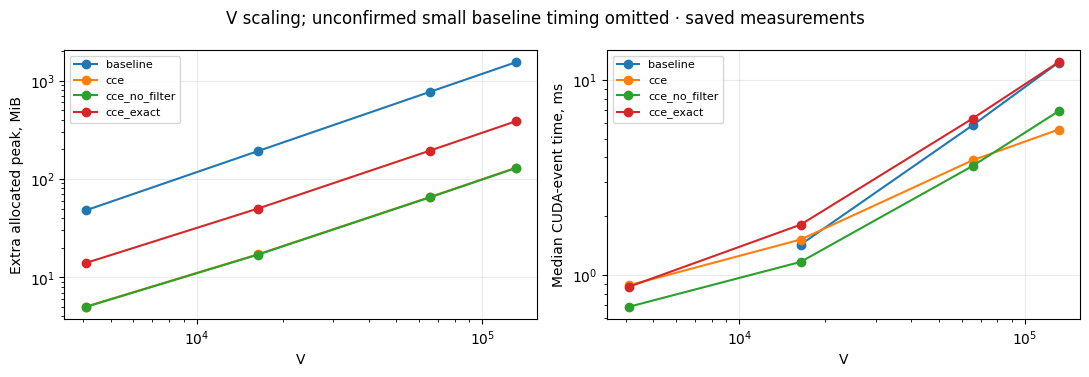

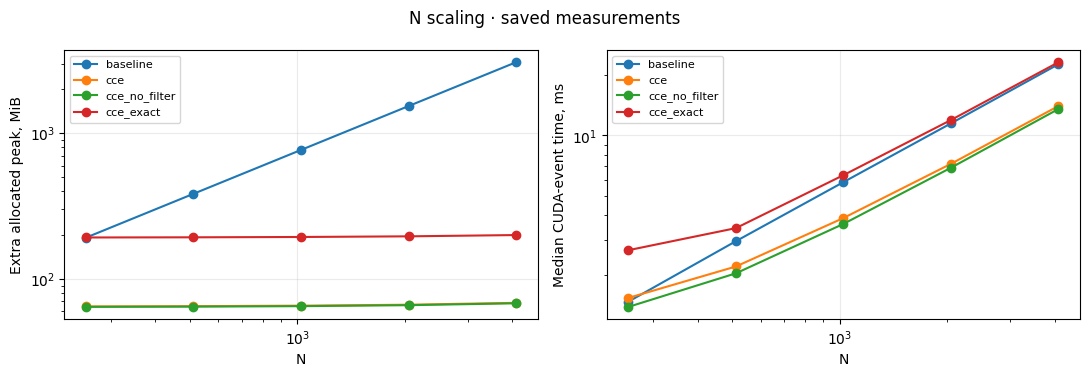

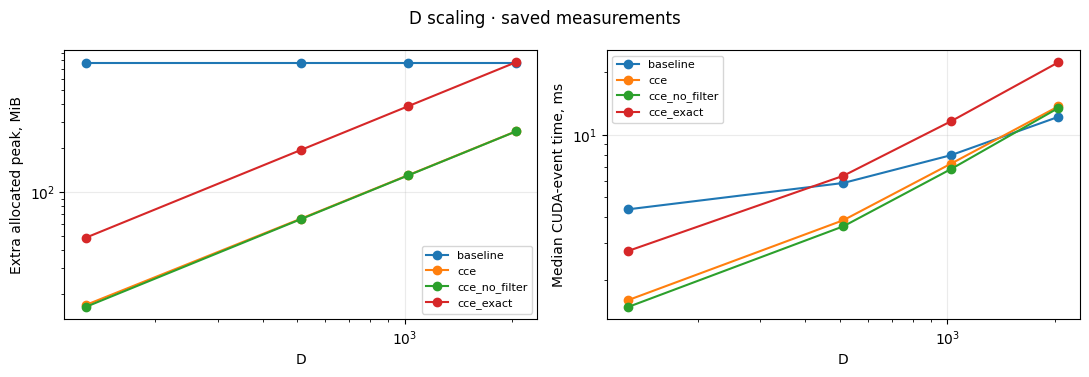

In [22]:
def plot_scaling(rows, axis, fixed, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for method in METHODS:
        selected = sorted([r for r in rows if r['status']=='ok' and r['kind']=='fw_bw'
                           and r['method']==method and all(r[k]==v for k,v in fixed.items())], key=lambda r:r[axis])
        axes[0].plot([r[axis] for r in selected], [r['extra_bytes']/2**20 for r in selected], 'o-', label=method)
        timed = [r for r in selected if not (r['method']=='baseline' and (r['n'],r['v'],r['d'])==(1024,4096,512))]
        axes[1].plot([r[axis] for r in timed], [r['median_ms'] for r in timed], 'o-', label=method)
    for ax, label in zip(axes, ['Extra allocated peak, MiB', 'Median CUDA-event time, ms']):
        ax.set(xlabel=axis.upper(), ylabel=label, xscale='log', yscale='log')
        ax.grid(alpha=.25)
        ax.legend(fontsize=8)
    fig.suptitle(title + ' · saved measurements')
    fig.tight_layout()
    plt.show()

plot_scaling(main_rows, 'v', {'n':1024, 'd':512}, 'V scaling; unconfirmed small baseline timing omitted')
plot_scaling(main_rows, 'n', {'v':65536, 'd':512}, 'N scaling')
plot_scaling(main_rows, 'd', {'n':1024, 'v':65536}, 'D scaling')

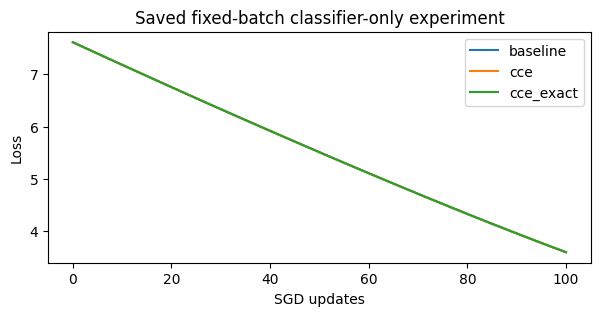

| method | step | loss |
| --- | --- | --- |
| baseline | 0 | 7.60914 |
| baseline | 100 | 3.60045 |
| cce | 0 | 7.60914 |
| cce | 100 | 3.60055 |
| cce_exact | 0 | 7.60914 |
| cce_exact | 100 | 3.60045 |

In [23]:
training = read_json('results/main/toy_training.json')
fig, ax = plt.subplots(figsize=(7,3))
for method in ('baseline','cce','cce_exact'):
    rows = [r for r in training if r['method']==method]
    ax.plot([r['step'] for r in rows], [r['loss'] for r in rows], label=method)
ax.set(xlabel='SGD updates', ylabel='Loss', title='Saved fixed-batch classifier-only experiment')
ax.legend()
plt.show()
table([r for r in training if r['step'] in (0,100)], ['method','step','loss'])

<a id="section-7"></a>

## 7. Отдельный backward и абляции

Нельзя получать backward вычитанием двух независимых медиан. Здесь свежий forward
строится до start event каждого sample; измеряется только `loss.backward()`.
Проверяются два масштаба logits и пять режимов на фиксированной shape.
Различие режимов не доказывает причину различия timings.

In [24]:
def run_diagnostics(args):
    out=Path(args.output)
    out.mkdir(parents=True,exist_ok=True)
    if (out/'diagnostics.json').exists():
        raise FileExistsError(out)
    configure()
    write_json(out/'environment.json', environment(args))
    rows=[]
    for scale in (1,4):
        e,c,y=make_data(512,32768,256,scale=scale)
        for method in ('baseline','cce','cce_no_filter','cce_exact','cce_filter_fp32'):
            result=measure(method,'fw_bw',e,c,y,10,10,3)
            row=dict(scale=scale,n=512,v=32768,d=256,method=method,fw_bw=result)
            samples=[]
            # Fresh graph outside each timed interval; backward only.
            for k in range(35):
                e.grad=c.grad=None
                loss=loss_fn(method,e,c,y)
                torch.cuda.synchronize()
                a,b=torch.cuda.Event(enable_timing=True),torch.cuda.Event(enable_timing=True)
                a.record()
                loss.backward()
                b.record()
                b.synchronize()
                if k>=5:
                    samples.append(a.elapsed_time(b))
                del loss
            row['backward_median_ms']=float(np.median(samples))
            row['backward_samples_ms']=samples
            rows.append(row)
            print(scale,method,'total',result['median_ms'],'bw',row['backward_median_ms'],flush=True)
        del e,c,y
        gc.collect()
        torch.cuda.empty_cache()
    write_json(out/'diagnostics.json',rows)
    write_json(out/'provenance.json',dict(source_sha256=hashlib.sha256((ROOT / 'cce_reproduction.ipynb').read_bytes()).hexdigest(),
        environment_reference='environment.json',seed=42,backward_warmup=5,backward_repeats=30,
        total_warmup=10,total_repeats=30,tf32=False,dtype='bfloat16'))

In [25]:
if RUN_DIAGNOSTICS:
    run_diagnostics(SimpleNamespace(output=str(new_output('diagnostics'))))
display(Markdown('**Архив: N=512, V=32768, D=256.**'))
table([dict(scale=r['scale'], method=r['method'], fw_bw_ms=r['fw_bw']['median_ms'],
            backward_ms=r['backward_median_ms']) for r in read_json('results/diagnostics/diagnostics.json')],
      ['scale','method','fw_bw_ms','backward_ms'])

**Архив: N=512, V=32768, D=256.**

| scale | method | fw_bw_ms | backward_ms |
| --- | --- | --- | --- |
| 1 | baseline | 1.21781 | 0.7812 |
| 1 | cce | 1.0867 | 0.754304 |
| 1 | cce_no_filter | 0.835312 | 0.578528 |
| 1 | cce_exact | 1.34806 | 1.06333 |
| 1 | cce_filter_fp32 | 1.55808 | 1.26789 |
| 4 | baseline | 1.22354 | 0.778336 |
| 4 | cce | 1.10618 | 0.783472 |
| 4 | cce_no_filter | 0.893984 | 0.60088 |
| 4 | cce_exact | 1.38354 | 1.13098 |
| 4 | cce_filter_fp32 | 1.62365 | 1.30107 |

<a id="section-8"></a>

## 8. Повторный benchmark по методике семинара

3 shapes × 3 метода × 2 протокола × 3 trials = 54 записи, порядок перемешан с seed 42.
`repeat_cache`: 30 CUDA-event samples с синхронизацией после каждого.
`l2_flush`: `triton.testing.do_bench(warmup=25, rep=100, return_mode='all')`;
25 и 100 — бюджеты в миллисекундах. Очистка cache находится до start event.
В обоих measured calls gradients сбрасываются через `grad=None`.

Протоколы отличаются **также синхронизацией**: `do_bench` синхронизирует серию целиком.
Поэтому их разность не является отдельным измерением эффекта L2.

In [26]:
def run_cache(args):
    out=Path(args.output)
    out.mkdir(parents=True,exist_ok=True)
    if (out/'environment.json').exists(): raise FileExistsError(out)
    configure()
    write_json(out/'environment.json',environment(args))
    rng=random.Random(42)
    rows=[]
    for n,v,d in [(1024,4096,512),(1024,65536,512),(1024,65536,2048)]:
        e,c,y=make_data(n,v,d)
        for trial in range(3):
            combinations=[(m,mode) for m in ('baseline','cce','cce_no_filter') for mode in ('repeat_cache','l2_flush')]
            rng.shuffle(combinations)
            for method,mode in combinations:
                def operation():
                    e.grad=c.grad=None
                    value=loss_fn(method,e,c,y)
                    value.backward()
                for _ in range(10):operation()
                torch.cuda.synchronize()
                if mode=='l2_flush':
                    samples=triton.testing.do_bench(operation,warmup=25,rep=100,return_mode='all')
                else:
                    samples=[]
                    for _ in range(30):
                        a,b=torch.cuda.Event(enable_timing=True),torch.cuda.Event(enable_timing=True)
                        a.record()
                        operation()
                        b.record()
                        b.synchronize()
                        samples.append(a.elapsed_time(b))
                row=dict(n=n,v=v,d=d,trial=trial,method=method,mode=mode,
                         timestamp_utc=datetime.now(timezone.utc).isoformat(),
                         median_ms=float(np.median(samples)),p10_ms=float(np.percentile(samples,10)),
                         p90_ms=float(np.percentile(samples,90)),samples_ms=samples)
                rows.append(row)
                write_json(out/'measurements.json',rows)
                print(n,v,d,trial,method,mode,round(row['median_ms'],3),flush=True)
        del e,c,y
        gc.collect()
        torch.cuda.empty_cache()

In [27]:
if RUN_CACHE:
    run_cache(SimpleNamespace(output=str(new_output('cache_benchmark'))))
cache_rows = read_json('results/cache_benchmark/measurements.json')
assert len(cache_rows) == 54
display(Markdown('**Архив: median-of-medians трёх trials, N=1024,V=4096,D=512.**'))
table([dict(method=m, **{mode:float(np.median([r['median_ms'] for r in cache_rows
        if r['v']==4096 and r['method']==m and r['mode']==mode])) for mode in ('repeat_cache','l2_flush')})
       for m in ('baseline','cce','cce_no_filter')], ['method','repeat_cache','l2_flush'])

**Архив: median-of-medians трёх trials, N=1024,V=4096,D=512.**

| method | repeat_cache | l2_flush |
| --- | --- | --- |
| baseline | 0.3148 | 0.271904 |
| cce | 0.937488 | 0.857408 |
| cce_no_filter | 0.722144 | 0.646144 |

<a id="section-9"></a>

## 9. Профилирование: kernels, allocations и пределы наблюдения

Отдельный запуск `torch.profiler`, 8 warmup и 3 записанные итерации для 12 сочетаний shape/method.
Включены CPU, CUDA, shapes, allocations, stacks и доступные PyTorch FLOPs.
Это не полный FLOP count произвольных Triton kernels. Duration под profiler
не подменяет обычный benchmark latency. DRAM counters, cache hits, stall reasons
и фактическое число пропущенных tiles здесь не измеряются.

Сохраняем gzip Chrome Trace, таблицу операторов и summary событий. Трассу можно распаковать
и открыть в локальном просмотрщике Chrome Trace/Perfetto.

In [28]:
from torch.profiler import profile, ProfilerActivity, record_function

def summarize_trace(path):
    trace=json.loads(path.read_text(encoding='utf-8'))
    events=trace.get('traceEvents',[])
    kernels=defaultdict(lambda:dict(calls=0,total_us=0.0,min_us=float('inf'),max_us=0.0))
    for e in events:
        if e.get('cat')=='kernel' and e.get('ph')=='X':
            r=kernels[e['name']]
            duration=e['dur']
            r['calls']+=1
            r['total_us']+=duration
            r['min_us']=min(r['min_us'],duration)
            r['max_us']=max(r['max_us'],duration)
    allocations=[e['args'] for e in events if e.get('name')=='[memory]' and e.get('args',{}).get('Device Type')==1]
    return dict(categories=dict(Counter(e.get('cat','') for e in events)),
                kernels=[dict(name=k,**v) for k,v in sorted(kernels.items(),key=lambda item:-item[1]['total_us'])],
                cuda_allocations=allocations)

In [29]:
def run_profiler(args):
    out=Path(args.output)
    out.mkdir(parents=True,exist_ok=True)
    if (out/'environment.json').exists(): raise FileExistsError(out)
    configure()
    write_json(out/'environment.json',environment(args))
    shapes=[('small',1024,4096,512),('large',4096,65536,512),('wide',1024,65536,2048)]
    if args.smoke: shapes=[shapes[0]]
    summaries=[]
    for label,n,v,d in shapes:
        e,c,y=make_data(n,v,d)
        for method in ('baseline','cce','cce_no_filter','cce_exact'):
            for _ in range(8):
                e.grad=c.grad=None
                value=loss_fn(method,e,c,y)
                value.backward()
                del value
            e.grad=c.grad=None
            torch.cuda.synchronize()
            gc.collect()
            with profile(activities=[ProfilerActivity.CPU,ProfilerActivity.CUDA],
                         record_shapes=True,profile_memory=True,with_stack=True,with_flops=True) as prof:
                for rep in range(3):
                    with record_function('iteration'):
                        with record_function('clear_grad'):
                            e.grad=c.grad=None
                        with record_function('forward'):
                            value=loss_fn(method,e,c,y)
                        with record_function('backward'):
                            value.backward()
                        del value
                torch.cuda.synchronize()
            name=f'{label}_{method}'
            tracepath=out/f'{name}.trace.json'
            prof.export_chrome_trace(str(tracepath))
            summary=summarize_trace(tracepath)
            summary.update(shape=[n,v,d],method=method,label=label,iterations=3)
            operations=[]
            for item in prof.key_averages(group_by_input_shape=True):
                operations.append(dict(name=item.key,count=item.count,shapes=item.input_shapes,
                    self_cpu_us=item.self_cpu_time_total,self_cuda_us=item.self_device_time_total,
                    cuda_total_us=item.device_time_total,self_cuda_memory_bytes=item.self_device_memory_usage,
                    cuda_memory_bytes=item.device_memory_usage,flops=item.flops))
            summary['operations']=operations
            summary['trace_has_cuda_kernels']=bool(summary['kernels'])
            write_json(out/f'{name}.summary.json',summary)
            (out/f'{name}.operators.txt').write_text(prof.key_averages().table(sort_by='self_cuda_time_total',row_limit=30),encoding='utf-8')
            # Compress only our freshly generated trace; this is reversible.
            with gzip.open(out/f'{name}.trace.json.gz','wb') as f: f.write(tracepath.read_bytes())
            tracepath.unlink()
            summaries.append({k:summary[k] for k in ('shape','method','label','iterations','trace_has_cuda_kernels')})
            print(name,'cuda kernels',sum(k['calls'] for k in summary['kernels']),'memory events',len(summary['cuda_allocations']),flush=True)
        del e,c,y
        gc.collect()
        torch.cuda.empty_cache()
    write_json(out/'index.json',summaries)

In [30]:
if RUN_PROFILER:
    run_profiler(SimpleNamespace(output=str(new_output('profiles')), smoke=False))

def profile_row(summary):
    iterations = summary['iterations']
    return dict(method=summary['method'], launches=sum(k['calls'] for k in summary['kernels'])/iterations,
                kernel_ms=sum(k['total_us'] for k in summary['kernels'])/iterations/1000,
                largest_allocation_MiB=max(a.get('Bytes',0) for a in summary['cuda_allocations'])/2**20)

display(Markdown('**Архив profiler: N=4096,V=65536,D=512; величины на итерацию.**'))
table([profile_row(read_json(f'results/profiles/large_{m}.summary.json')) for m in METHODS],
      ['method','launches','kernel_ms','largest_allocation_MiB'])

**Архив profiler: N=4096,V=65536,D=512; величины на итерацию.**

| method | launches | kernel_ms | largest_allocation_MiB |
| --- | --- | --- | --- |
| baseline | 11 | 22.582 | 1024 |
| cce | 26 | 13.4115 | 64 |
| cce_no_filter | 17 | 12.8815 | 64 |
| cce_exact | 19 | 22.827 | 128 |

<a id="section-10"></a>

## 10. Gemma 2 2B / Alpaca: подготовка реальных входов

Две opt-in стадии: загрузить pinned snapshots и извлечь 8192 валидные next-token позиции.
Для загрузки Gemma требуется уже предоставленный доступ в Hugging Face.
Веса занимают около 5.3 GB, подготовленные E/C/y — около 1.2 GB.
Секреты и веса в репозиторий не записываются.

Модель: `google/gemma-2-2b-it`, revision `299a8560bedf22ed1c72a8a11e7dce4a7f9f51f8`.
Dataset: `yahma/alpaca-cleaned`, revision `12567cabf869d7c92e573c7c783905fc160e9639`.
Shuffle seed 42, каждый пример обрезан до 512 tokens; decoder в eval/no_grad,
eager attention, use_cache=False. Берутся hidden[:-1] для labels[1:] после masking.
В сохранённой серии использованы 52 примера. Prompt и masking следуют upstream;
sample order, extraction, software и GPU отличаются от статьи.

In [31]:
MODEL = 'google/gemma-2-2b-it'
REVISION = '299a8560bedf22ed1c72a8a11e7dce4a7f9f51f8'
DATASET = 'yahma/alpaca-cleaned'
DATASET_REVISION = '12567cabf869d7c92e573c7c783905fc160e9639'

def download_real_inputs():
    from huggingface_hub import snapshot_download, hf_hub_download
    snapshot_download(MODEL, revision=REVISION, local_dir=ROOT/'.models/gemma-2-2b-it',
                      allow_patterns=['*.json','*.safetensors','tokenizer.model','*.jinja'], max_workers=3)
    hf_hub_download(DATASET, 'alpaca_data_cleaned.json', repo_type='dataset', revision=DATASET_REVISION,
                    local_dir=ROOT/'.data/alpaca')
    write_json(ROOT/'.data/download_provenance.json', dict(model=MODEL, model_revision=REVISION,
               dataset=DATASET, dataset_revision=DATASET_REVISION, model_local='.models/gemma-2-2b-it',
               dataset_local='.data/alpaca/alpaca_data_cleaned.json'))

if DOWNLOAD_REAL:
    download_real_inputs()

In [32]:
def tokenized_example(tokenizer,row):
    # Prompt wording and target-span masking follow upstream training/train.py.
    # Apple source: 3de376c; no system prompt for Gemma2, as in its benchmark.
    source='Below is an instruction that describes a task'
    if row['input']:
        source+=', paired with an input that provides further context. Write a response that appropriately completes the request.\n\n### Instruction:\n'+row['instruction']+'\n\n### Input:\n'+row['input']+'\n\n'
    else:
        source+='. Write a response that appropriately completes the request.\n\n### Instruction:\n'+row['instruction']+'\n\n'
    encoded=tokenizer.apply_chat_template([{'role':'user','content':source},{'role':'assistant','content':row['output']}],add_generation_prompt=False,return_dict=True)
    ids=encoded['input_ids']
    target=tokenizer.encode(row['output'],add_special_tokens=False)
    start=None
    for offset in reversed(range(len(ids)-len(target)+1)):
        if ids[offset:offset+len(target)]==target:
            start=offset
            break
    if start is None or not target: return None
    ids=torch.tensor(ids[:512],dtype=torch.long)
    labels=ids.clone()
    labels[:start]=-100
    return ids,labels

In [33]:
def prepare_real_inputs(args):
    from transformers import AutoModelForCausalLM, AutoTokenizer
    configure()
    target=ROOT/'.data'/'gemma_activations.pt'
    if target.exists():raise FileExistsError(target)
    download=json.loads((ROOT/'.data/download_provenance.json').read_text())
    local=ROOT/download['model_local']
    tokenizer=AutoTokenizer.from_pretrained(local,local_files_only=True)
    model=AutoModelForCausalLM.from_pretrained(local,local_files_only=True,dtype=torch.bfloat16,
                                            attn_implementation='eager').to('cuda').eval()
    decoder=model.get_decoder()
    data_path=ROOT/download['dataset_local']
    records=json.loads(data_path.read_text(encoding='utf-8'))
    order=list(range(len(records)))
    random.Random(42).shuffle(order)
    embeddings,labels,used=[],[],[]
    count=0
    skipped=0
    with torch.no_grad():
        for index in order:
            result=tokenized_example(tokenizer,records[index])
            if result is None:
                skipped+=1
                continue
            ids,y=result
            valid=y[1:]!=-100
            if not valid.any():
                skipped+=1
                continue
            hidden=decoder(input_ids=ids[None].to('cuda'),use_cache=False).last_hidden_state
            embeddings.append(hidden[0,:-1][valid.to('cuda')].cpu())
            labels.append(y[1:][valid])
            used.append(index)
            count+=int(valid.sum())
            del hidden
            if len(used)%10==0:print('examples',len(used),'valid tokens',count,flush=True)
            if count>=args.tokens:break
    if count<args.tokens:raise RuntimeError('Insufficient extracted target tokens')
    e=torch.cat(embeddings)[:args.tokens].contiguous()
    y=torch.cat(labels)[:args.tokens].contiguous()
    c=model.get_output_embeddings().weight.detach().cpu().contiguous()
    softcap=getattr(model.config,'final_logit_softcapping',None)
    torch.save(dict(e=e,c=c,y=y,softcap=softcap),target)
    provenance=dict(**download,n=args.tokens,v=c.shape[0],d=c.shape[1],softcap=softcap,
        seed=42,max_sequence_length=512,example_indices=used,skipped_examples=skipped,
        dataset_sha256=hashlib.sha256(data_path.read_bytes()).hexdigest(),
        activation_file_sha256=hashlib.sha256(target.read_bytes()).hexdigest(),
        preprocessing='upstream prompt wording and response-span masking; single-sequence extraction; seed42 shuffle; truncate512; valid next-token positions only',
        input_dtype='bfloat16',attention='eager',use_cache=False)
    (ROOT/'.data/gemma_provenance.json').write_text(json.dumps(provenance,indent=2),encoding='utf-8')
    del model,decoder,c,e,embeddings
    gc.collect()
    torch.cuda.empty_cache()
    print('ACTIVATIONS_SAVED',args.tokens,flush=True)

In [34]:
if PREPARE_REAL:
    prepare_real_inputs(SimpleNamespace(tokens=8192))
real_environment = read_json('results/gemma2/environment.json')
provenance = real_environment['data_provenance']
table([dict(n=provenance['n'],v=provenance['v'],d=provenance['d'],softcap=provenance['softcap'],
            examples=len(provenance['example_indices']),seed=provenance['seed'])],
      ['n','v','d','softcap','examples','seed'])

| n | v | d | softcap | examples | seed |
| --- | --- | --- | --- | --- | --- |
| 8192 | 256000 | 2304 | 30 | 52 | 42 |

<a id="section-11"></a>

## 11. Реальный classifier head: отдельный baseline и reference

Авторский baseline выполняет **BF16 matmul → BF16 tanh softcap → FP32 CE**.
Его нельзя смешивать с baseline синтетической серии, где softcap считается в FP32.
Для correctness используются первые 32 позиции и полный vocabulary 256000:
reference в FP32 с выключенным TF32; ошибки gradient norms аккумулируются в FP64 на CPU.
Это другой reference, чем FP64 в синтетической серии.

In [35]:
REAL_METHODS = ('baseline_author', 'cce', 'cce_no_filter', 'cce_exact')

def real_loss(method,e,c,y,cap):
    if method=='baseline_author':
        # Exact operation order of upstream benchmark.baseline (BF16 softcap).
        z=e @ c.T
        z=torch.tanh(z/cap)*cap
        return F.cross_entropy(z.float(),y)
    return loss_fn(method,e,c,y,cap)

In [36]:
def compare_chunks(actual,reference,chunk=1024):
    maximum=diffnorm=refnorm=0.0
    for a,b in zip(actual.detach().split(chunk),reference.split(chunk)):
        a,b=a.double().cpu(),b.double().cpu()
        diffnorm+=(a-b).square().sum().item()
        refnorm+=b.square().sum().item()
        maximum=max(maximum,(a-b).abs().max().item())
    return dict(max_abs=maximum,relative_l2=(diffnorm/max(refnorm,1e-60))**.5)

In [37]:
def real_correctness(data,out):
    # Full vocabulary and real weights, FP32 reference; compare grads in chunks.
    e=data['e'][:32].cuda().requires_grad_()
    c=data['c'].cuda().requires_grad_()
    y=data['y'][:32].cuda()
    cap=data['softcap']
    er=e.detach().float().requires_grad_()
    cr=c.detach().float().requires_grad_()
    z=er @ cr.T
    ref=F.cross_entropy(cap*torch.tanh(z/cap),y)
    ref.backward()
    refvalue=ref.item()
    geref,gcref=er.grad.cpu(),cr.grad.cpu()
    del er,cr,z,ref
    gc.collect()
    torch.cuda.empty_cache()
    rows=[]
    for method in (*REAL_METHODS,'baseline'):
        e.grad=c.grad=None
        value=real_loss(method,e,c,y,cap)
        value.backward()
        row=dict(method=method,n=32,v=c.shape[0],d=c.shape[1],reference='FP32, TF32 disabled, identical BF16 inputs',
                 loss=value.item(),reference_loss=refvalue,loss_abs=abs(value.item()-refvalue),
                 e=compare_chunks(e.grad,geref),c=compare_chunks(c.grad,gcref))
        row['passed']=row['loss_abs']<.05 and row['e']['relative_l2']<.05 and row['c']['relative_l2']<.05
        rows.append(row)
        del value
        print('correctness',method,row['loss_abs'],row['e']['relative_l2'],row['c']['relative_l2'],flush=True)
    write_json(out/'correctness.json',rows)
    del e,c,y,geref,gcref
    gc.collect()
    torch.cuda.empty_cache()

### Измерения на настоящих activations

5 warmup, 30 CUDA-event samples, отдельный allocated peak; N=128,512,1024,2048,8192.
Измеряется только head, без backbone inference/training.
Для baseline применяется бюджет `16NV+4VD+4ND > 0.8 × VRAM`.
Это эвристика предварительного пропуска, не доказанный upper bound и не наблюдённый OOM.
При N=8192 в архиве две строки baseline имеют `not_run_memory_guard`.

In [38]:
def real_measure(method,kind,e,c,y,cap):
    def op():
        e.grad=c.grad=None
        value=real_loss(method,e,c,y,cap)
        if kind=='fw_bw':value.backward()
        return value
    for _ in range(5):
        value=op()
        del value
    torch.cuda.synchronize()
    e.grad=c.grad=None
    gc.collect()
    base=torch.cuda.memory_allocated()
    torch.cuda.reset_peak_memory_stats()
    value=op()
    torch.cuda.synchronize()
    peak=torch.cuda.max_memory_allocated()
    loss=value.item()
    del value
    samples=[]
    for _ in range(30):
        e.grad=c.grad=None
        a,b=torch.cuda.Event(enable_timing=True),torch.cuda.Event(enable_timing=True)
        a.record()
        value=real_loss(method,e,c,y,cap)
        if kind=='fw_bw':value.backward()
        b.record()
        b.synchronize()
        samples.append(a.elapsed_time(b))
        del value
    e.grad=c.grad=None
    return dict(loss=loss,base_bytes=base,peak_bytes=peak,extra_bytes=peak-base,
                median_ms=float(np.median(samples)),p10_ms=float(np.percentile(samples,10)),
                p90_ms=float(np.percentile(samples,90)),samples_ms=samples)

### Три дополнительные profiler-трассы

N=1024, baseline_author/default/no-filter, по 3 итерации после прогрева.
Разбор kernel durations отделён от таблицы обычного времени.

In [39]:
def profile_real(data,out):
    e=data['e'][:1024].cuda().requires_grad_()
    c=data['c'].cuda().requires_grad_()
    y=data['y'][:1024].cuda()
    for method in ('baseline_author','cce','cce_no_filter'):
        for _ in range(5):
            e.grad=c.grad=None
            value=real_loss(method,e,c,y,data['softcap'])
            value.backward()
            del value
        e.grad=c.grad=None
        torch.cuda.synchronize()
        with profile(activities=[ProfilerActivity.CPU,ProfilerActivity.CUDA],record_shapes=True,profile_memory=True) as prof:
            for _ in range(3):
                e.grad=c.grad=None
                with record_function('forward'):
                    value=real_loss(method,e,c,y,data['softcap'])
                with record_function('backward'):
                    value.backward()
                del value
            torch.cuda.synchronize()
        path=out/f'{method}.trace.json'
        prof.export_chrome_trace(str(path))
        summary=summarize_trace(path)
        summary.update(n=1024,v=c.shape[0],d=c.shape[1],method=method,iterations=3)
        write_json(out/f'{method}.profile.json',summary)
        with gzip.open(out/f'{method}.trace.json.gz','wb') as f:f.write(path.read_bytes())
        path.unlink()
    del e,c,y
    gc.collect()
    torch.cuda.empty_cache()

In [40]:
def run_real(args):
    out=Path(args.output)
    out.mkdir(parents=True,exist_ok=True)
    if (out/'environment.json').exists():raise FileExistsError(out)
    configure()
    env=environment(args)
    import importlib.metadata
    env['transformers']=importlib.metadata.version('transformers')
    env['huggingface_hub']=importlib.metadata.version('huggingface_hub')
    env['data_provenance']=json.loads((ROOT/'.data/gemma_provenance.json').read_text())
    env['warmup']=5
    env['repeats']=30
    env['baseline']='upstream BF16 matmul -> BF16 tanh softcap -> FP32 CE'
    write_json(out/'environment.json',env)
    data=torch.load(ROOT/'.data/gemma_activations.pt',map_location='cpu',weights_only=True)
    real_correctness(data,out)
    rows=[]
    for index,n in enumerate((128,512,1024,2048,8192)):
        e=data['e'][:n].cuda().requires_grad_()
        c=data['c'].cuda().requires_grad_()
        y=data['y'][:n].cuda()
        v,d=c.shape
        for kind in ('fw','fw_bw'):
            for method in (REAL_METHODS if index%2==0 else REAL_METHODS[::-1]):
                row=dict(n=n,v=v,d=d,method=method,kind=kind,softcap=data['softcap'],status='ok')
                # Heuristic allocation budget; not a proven upper bound.
                # This is a planned skip, NOT an observed OOM.
                estimate=16*n*v+4*v*d+4*n*d
                if method=='baseline_author' and estimate>.8*torch.cuda.get_device_properties(0).total_memory:
                    row.update(status='not_run_memory_guard',conservative_bytes=estimate)
                else:
                    try:row.update(real_measure(method,kind,e,c,y,data['softcap']))
                    except torch.cuda.OutOfMemoryError:
                        row['status']='oom'
                        e.grad=c.grad=None
                        gc.collect()
                        torch.cuda.empty_cache()
                rows.append(row)
                write_json(out/'measurements.json',rows)
                print(n,kind,method,row['status'],row.get('median_ms'),row.get('extra_bytes'),flush=True)
        del e,c,y
        gc.collect()
        torch.cuda.empty_cache()
    profile_real(data,out)
    write_json(out/'completion.json',dict(completed=True,rows=len(rows),measured=sum(r['status']=='ok' for r in rows)))

In [41]:
if RUN_REAL:
    run_real(SimpleNamespace(output=str(new_output('gemma2'))))

real_checks = read_json('results/gemma2/correctness.json')
assert len(real_checks)==5 and all(r['passed'] for r in real_checks)
display(Markdown('**Архив Gemma correctness: N=32, V=256000, D=2304; FP32 reference.**'))
table([dict(method=r['method'],loss_abs=r['loss_abs'],dE_relL2=r['e']['relative_l2'],
            dC_relL2=r['c']['relative_l2']) for r in real_checks], ['method','loss_abs','dE_relL2','dC_relL2'])

**Архив Gemma correctness: N=32, V=256000, D=2304; FP32 reference.**

| method | loss_abs | dE_relL2 | dC_relL2 |
| --- | --- | --- | --- |
| baseline_author | 0.0106997 | 0.0153473 | 0.013987 |
| cce | 0.00646806 | 0.00703809 | 0.00522322 |
| cce_no_filter | 0.00646901 | 0.0083895 | 0.00521321 |
| cce_exact | 0.0064683 | 0.00647786 | 0.00521305 |
| baseline | 0.00642371 | 0.00648222 | 0.00521916 |

<a id="section-12"></a>

## 12. Разбор результатов Gemma

Указываем shape и метод baseline для каждого отношения. Результат на одной GPU
не переносится автоматически на другую среду, а сравнение с синтетикой не изолирует
влияние распределения данных: одновременно отличаются shape и softcap.

### Table 1: сравнение памяти при N8192

Метрика совпадает с авторским `mem_delta`: extra allocated peak, bytes / 2²⁰.
Upstream называет эти единицы MB; здесь используется обозначение MiB.

| Величина при N=8192 | Table 1, «MB» | HW2, MiB | Статус HW2 |
|---|---:|---:|---|
| CCE, loss | 1 | 1.040 | измерено |
| CCE без filtering/sorting, loss | 0.09 | 0.094 | измерено |
| CCE, loss+gradient | 1164 | 1164.269 | измерено |
| CCE без filtering/sorting, loss+gradient | 1162 | 1162.316 | измерено |
| Lower bound: BF16 ∇E + ∇C | 1161 | 1161.000 | расчёт размера |
| Baseline, loss | 24000 | 24000.001 | **экстраполяция, не измерение** |
| Baseline, loss+gradient | 28000 | 28000.001 | **экстраполяция, не измерение** |

Память CCE измерена; lower bound — расчёт `2D(N+V)`. Две строки baseline — **экстраполяция**
аффинных зависимостей из N512,1024,2048; запуск при N8192 не выполнялся.
Это согласование с округлёнными числами статьи, не побитовое равенство и не наблюдённый OOM.
Формулы, residuals, отличия batch/timing и соответствие presets строкам статьи:
[отчёт §10.8–10.10](REPORT.md#table1-comparison), [расчёт из исходных JSON](results/table1_comparison.json).


**Архив Gemma: N=1024,V=256000,D=2304,softcap=30,forward+backward.**

| method | extra_MiB | full_peak_MiB | median_ms |
| --- | --- | --- | --- |
| baseline_author | 3500 | 4646.76 | 62.7513 |
| cce | 1132.73 | 2279.49 | 31.8769 |
| cce_no_filter | 1130.78 | 2277.54 | 59.3619 |
| cce_exact | 3385.28 | 4532.04 | 99.4397 |

Отношение extra peak: 3.09; времени: 1.97


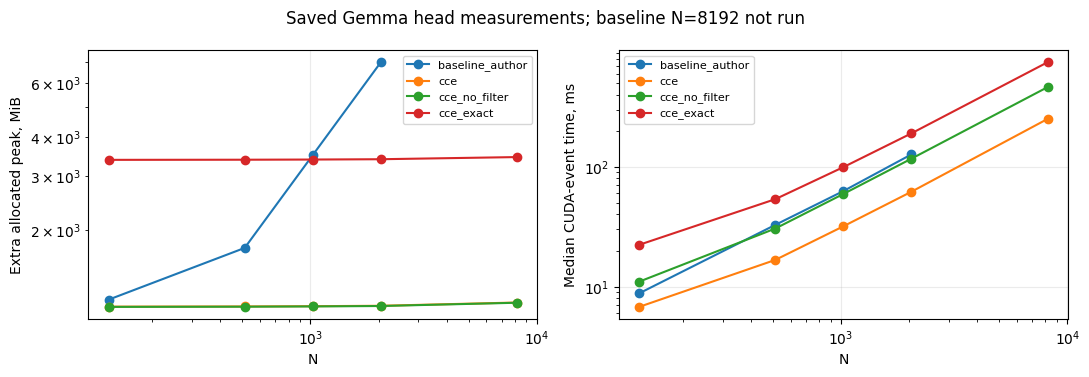

In [42]:
real_rows = read_json('results/gemma2/measurements.json')
assert len(real_rows)==40
assert sum(r['status']=='ok' for r in real_rows)==38
assert sum(r['status']=='not_run_memory_guard' for r in real_rows)==2
selected = [r for r in real_rows if r['n']==1024 and r['kind']=='fw_bw']
display(Markdown('**Архив Gemma: N=1024,V=256000,D=2304,softcap=30,forward+backward.**'))
table([dict(method=r['method'],extra_MiB=r['extra_bytes']/2**20,
            full_peak_MiB=r['peak_bytes']/2**20,median_ms=r['median_ms']) for r in selected],
      ['method','extra_MiB','full_peak_MiB','median_ms'])
base = next(r for r in selected if r['method']=='baseline_author')
cce = next(r for r in selected if r['method']=='cce')
print(f"Отношение extra peak: {base['extra_bytes']/cce['extra_bytes']:.2f}; времени: {base['median_ms']/cce['median_ms']:.2f}")

fig, axes = plt.subplots(1,2,figsize=(11,3.8))
for method in REAL_METHODS:
    rows = sorted([r for r in real_rows if r['method']==method and r['kind']=='fw_bw' and r['status']=='ok'],key=lambda r:r['n'])
    axes[0].plot([r['n'] for r in rows],[r['extra_bytes']/2**20 for r in rows],'o-',label=method)
    axes[1].plot([r['n'] for r in rows],[r['median_ms'] for r in rows],'o-',label=method)
for ax,label in zip(axes,['Extra allocated peak, MiB','Median CUDA-event time, ms']):
    ax.set(xlabel='N',ylabel=label,xscale='log',yscale='log')
    ax.grid(alpha=.25)
    ax.legend(fontsize=8)
fig.suptitle('Saved Gemma head measurements; baseline N=8192 not run')
fig.tight_layout()
plt.show()

In [43]:
display(Markdown('**Архив Gemma profiler: N=1024, средние kernel durations на итерацию.**'))
profile_rows=[]
for method in ('baseline_author','cce','cce_no_filter'):
    summary = read_json(f'results/gemma2/{method}.profile.json')
    row = profile_row(summary)
    for label, match in [('cce_forward_ms','_cce_lse_forward_kernel'),('cce_backward_ms','_cce_backward_kernel')]:
        kernels = [k for k in summary['kernels'] if match in k['name']]
        if kernels:
            row[label] = sum(k['total_us'] for k in kernels)/summary['iterations']/1000
    profile_rows.append(row)
table(profile_rows,['method','launches','kernel_ms','cce_forward_ms','cce_backward_ms','largest_allocation_MiB'])

**Архив Gemma profiler: N=1024, средние kernel durations на итерацию.**

| method | launches | kernel_ms | cce_forward_ms | cce_backward_ms | largest_allocation_MiB |
| --- | --- | --- | --- | --- | --- |
| baseline_author | 17 | 62.8391 | — | — | 1126 |
| cce | 26 | 31.5458 | 13.4145 | 16.7036 | 1126 |
| cce_no_filter | 17 | 59.0646 | 13.2939 | 44.3898 | 1126 |

<a id="section-13"></a>

## 13. Сверка исходных данных и трасс

Ниже повторно читаем все 15 `.trace.json.gz`. Проверяем число kernels, их суммарную duration
и список CUDA allocation events против сохранённых summaries. Это проверка согласованности
артефактов; независимые GPU hardware counters из неё не появляются.
Дополнительно проверяем, что medians в JSON соответствуют сохранённым samples.

In [44]:
trace_count=0
for folder, suffix in [('profiles','.summary.json'),('gemma2','.profile.json')]:
    for path in sorted((ROOT/'results'/folder).glob('*.trace.json.gz')):
        with gzip.open(path,'rt',encoding='utf-8') as stream:
            events=json.load(stream)['traceEvents']
        summary=json.loads(path.with_name(path.name.replace('.trace.json.gz',suffix)).read_text('utf-8'))
        actual=defaultdict(lambda:dict(calls=0,total_us=0.0))
        for event in events:
            if event.get('cat')=='kernel' and event.get('ph')=='X':
                actual[event['name']]['calls']+=1
                actual[event['name']]['total_us']+=event['dur']
        assert actual, path.name
        assert set(actual)=={k['name'] for k in summary['kernels']}
        for kernel in summary['kernels']:
            measured=actual[kernel['name']]
            assert measured['calls']==kernel['calls']
            assert np.isclose(measured['total_us'],kernel['total_us'],rtol=1e-12,atol=1e-9)
        allocations=[e['args'] for e in events if e.get('name')=='[memory]' and e.get('args',{}).get('Device Type')==1]
        assert allocations==summary['cuda_allocations']
        trace_count+=1
assert trace_count==15
for row in main_rows+real_rows+cache_rows:
    if row.get('status','ok')=='ok':
        assert np.isclose(np.median(row['samples_ms']),row['median_ms'],rtol=1e-12)
        if 'peak_bytes' in row:
            assert row['extra_bytes']==row['peak_bytes']-row['base_bytes']
print(f'Сверено {trace_count}/15 трасс; medians и extra peak согласованы с сырыми данными.')

Сверено 15/15 трасс; medians и extra peak согласованы с сырыми данными.


<a id="section-14"></a>

## 14. Что можно утверждать

- На Gemma N1024/V256000/D2304/softcap30 extra peak: 3500.001 → 1132.734 MiB,
  время: 62.751 → 31.877 ms. Это classifier head, без backbone.
- На синтетической N4096/V65536/D512 default CCE уменьшил extra peak с 3072.001 до 68.533 MiB,
  а median — с 22.710 до 14.034 ms. На D2048 default CCE медленнее baseline.
- На Gemma N8192 baseline не запускался по заранее заданному memory guard; это не наблюдённый OOM. Отношение baseline/CCE там не вычисляется.
- Проверены 60 синтетических и 5 реальных численных случаев в указанных допусках.
  Качество полной модели и её длительная сходимость не проверены.
- Трассы показывают launches, durations и allocations. Причины неповторившейся small timing,
  skipped tiles, DRAM throughput и измеренная аппаратными counters occupancy не установлены.

В [отчёте](REPORT.md) приведены подробные выкладки, таблицы, реестр доказательств
и текст доклада. [Презентация](presentation.html) содержит 12 основных слайдов и 5 приложений;
[PDF](presentation.pdf) доступен офлайн.

**Связь с объяснениями авторов.** Проигрыш при большем D согласуется с механизмом
параллелизма из Appendix C.2; выигрыш default против no-filter на Gemma — с механизмом
разрежённых вероятностей из §5.2 / Fig. 3. Это интерпретация, а не локальное доказательство
причинности: sparsity/rank curve и skipped tiles не измерены. Не воспроизведены также
`torch.compile` baseline, §5.3 training curves и Fig. 1 / Table A4. Подробности и ссылки —
[отчёт §10.8–10.10](REPORT.md#table1-comparison).
